In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
day8_input_path = "../data/analysis_data/APL_Day5_Delay_Risk_Analysis.csv"

df_day8 = pd.read_csv(
    day8_input_path,
    encoding="cp1252",
    low_memory=False
)

print("Day 8 dataset loaded successfully.")
print("Dataset shape:", df_day8.shape)

display(df_day8.head())

Day 8 dataset loaded successfully.
Dataset shape: (180519, 56)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Fname,Customer Id,Customer Lname,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Name,Product Price,Shipping Mode,Shipping_Delay_Days,Is_Delayed,Is_On_Time,Early_Delivery_Days,Delay_Severity,Delivery_Efficiency_Ratio,Revenue_Per_Unit,Profit_Margin,Discount_Level,Region_Market,Shipping_Mode_Rank,Is_Corporate_Customer,Order_Quantity_Category,Operational_Risk_Profile,Delivery_Status,Risk_Status
0,DEBIT,6,4,159.69,472.45,Late delivery,1,9,Cardio Equipment,Brownsville,EE. UU.,Richard,1,Hernandez,Consumer,TX,6303 Heather Plaza,78521.0,3,Footwear,25.953648,-97.507683,Pacific Asia,Mumbai,India,1,27.50,0.06,99.99,0.34,5,499.95,472.45,159.69,South Asia,Maharashtra,COMPLETE,Nike Men's Free 5.0+ Running Shoe,99.99,Standard Class,2,1,0,0,Major Delay,0.666667,99.99,0.319412,Low Discount,Pacific Asia - South Asia,4,0,Large,High Risk - Slower Shipping,Delayed,High Risk
1,DEBIT,4,4,48.71,167.96,Shipping on time,0,29,Shop By Sport,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,5,Golf,38.375595,-104.726021,LATAM,San Pedro Sula,Honduras,2,31.99,0.16,39.99,0.29,5,199.95,167.96,48.71,Central America,Cortés,ON_HOLD,Under Armour Girls' Toddler Spine Surge Runni,39.99,Standard Class,0,0,1,0,On Time / Early,1.000000,39.99,0.243611,Medium Discount,LATAM - Central America,4,0,Large,Lower Risk,On Time,Low Risk
2,DEBIT,4,4,87.36,181.99,Shipping on time,0,48,Water Sports,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,7,Fan Shop,38.375595,-104.726021,LATAM,San Pedro Sula,Honduras,2,18.00,0.09,199.99,0.48,1,199.99,181.99,87.36,Central America,Cortés,ON_HOLD,Pelican Sunstream 100 Kayak,199.99,Standard Class,0,0,1,0,On Time / Early,1.000000,199.99,0.436822,Low Discount,LATAM - Central America,4,0,Small,Lower Risk,On Time,Low Risk
3,DEBIT,6,4,-41.89,175.99,Late delivery,1,48,Water Sports,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,7,Fan Shop,38.375595,-104.726021,USCA,New York City,Estados Unidos,2,24.00,0.12,199.99,-0.24,1,199.99,175.99,-41.89,East of USA,Nueva York,COMPLETE,Pelican Sunstream 100 Kayak,199.99,Standard Class,2,1,0,0,Major Delay,0.666667,199.99,-0.209460,Medium Discount,USCA - East of USA,4,0,Small,High Risk - Slower Shipping,Delayed,High Risk
4,DEBIT,6,4,10.00,40.00,Late delivery,1,24,Women's Apparel,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,5,Golf,38.375595,-104.726021,USCA,New York City,Estados Unidos,2,10.00,0.20,50.00,0.25,1,50.00,40.00,10.00,East of USA,Nueva York,COMPLETE,Nike Men's Dri-FIT Victory Golf Polo,50.00,Standard Class,2,1,0,0,Major Delay,0.666667,50.00,0.200000,Medium Discount,USCA - East of USA,4,0,Small,High Risk - Slower Shipping,Delayed,High Risk


In [3]:
print("Total rows:", len(df_day8))
print("Total columns:", len(df_day8.columns))

print("Duplicate rows:", df_day8.duplicated().sum())

print("\nDataset columns:")
print(df_day8.columns.tolist())

Total rows: 180519
Total columns: 56
Duplicate rows: 0

Dataset columns:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Product Name', 'Product Price', 'Shipping Mode', 'Shipping_Delay_Days', 'Is_Delayed', 'Is_On_Time', 'Early_Delivery_Days', 'Delay_Severity', 'Delivery_Efficiency_Ratio', 'Revenue_Per_Unit', 'Profit_Margin', 'Discount_Leve

In [4]:
required_columns = [
    "Order Region",
    "Order State",
    "Is_Delayed",
    "Shipping_Delay_Days",
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Delivery Status",
    "Market"
]

missing_columns = [
    col for col in required_columns
    if col not in df_day8.columns
]

if missing_columns:
    print("Missing required columns:", missing_columns)
else:
    print("All required columns are available.")

All required columns are available.


In [5]:
regional_columns = [
    "Order Region",
    "Order State",
    "Is_Delayed",
    "Shipping_Delay_Days",
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Delivery Status",
    "Market"
]

display(
    df_day8[regional_columns]
    .isna()
    .sum()
    .to_frame(name="Missing_Values")
)

,Missing_Values
Order Region,0
Order State,0
Is_Delayed,0
Shipping_Delay_Days,0
Days for shipping (real),0
Days for shipment (scheduled),0
Delivery Status,0
Market,0


## Day 8 Working Copy

In [6]:
df_day8 = df_day8.copy()

print("Day 8 working copy created.")
print("Shape:", df_day8.shape)

Day 8 working copy created.
Shape: (180519, 56)


## Regioinal Shippment Distribution

### Count Shipments by region

In [7]:
regional_shipment_summary = (
    df_day8
    .groupby("Order Region", dropna=False)
    .size()
    .reset_index(name="Total_Shipments")
)

regional_shipment_summary = regional_shipment_summary.sort_values(
    "Total_Shipments",
    ascending=False
)

regional_shipment_summary["Shipment_Share_%"] = (
    regional_shipment_summary["Total_Shipments"]
    / len(df_day8)
    * 100
).round(2)

display(regional_shipment_summary)

,Order Region,Total_Shipments,Shipment_Share_%
3,Central America,28341,15.70
22,Western Europe,27109,15.02
12,South America,14935,8.27
11,Oceania,10148,5.62
10,Northern Europe,9792,5.42
15,Southeast Asia,9539,5.28
17,Southern Europe,9431,5.22
1,Caribbean,8318,4.61
21,West of USA,7993,4.43
13,South Asia,7731,4.28


### Visualize shipment diatribution

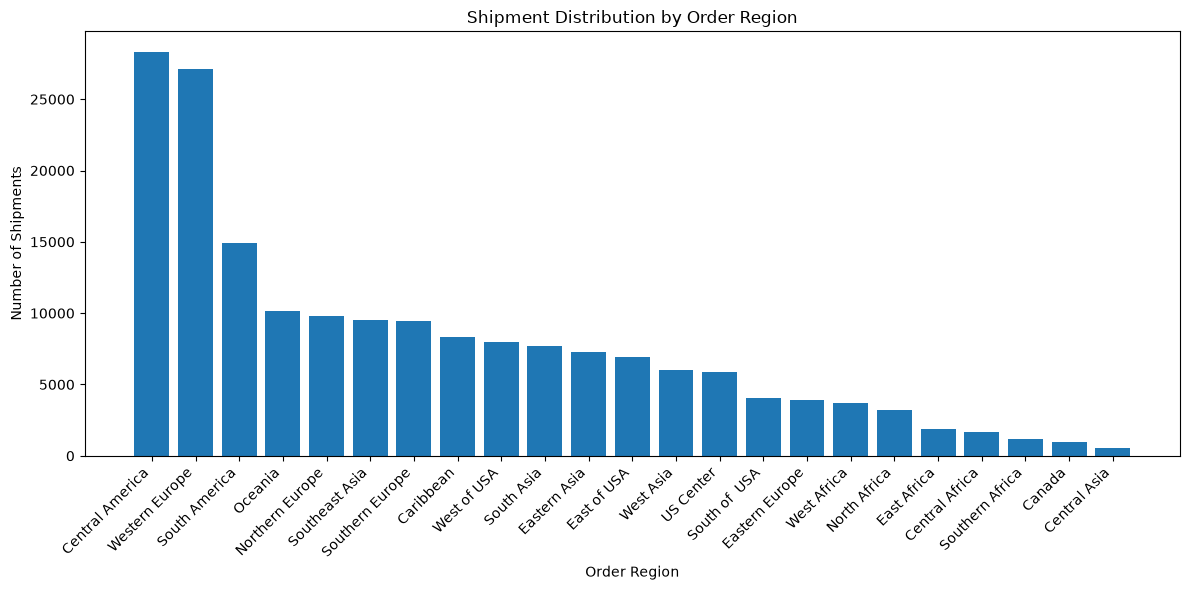

In [8]:
regional_shipment_plot = regional_shipment_summary.dropna(
    subset=["Order Region"]
)

plt.figure(figsize=(12, 6))

plt.bar(
    regional_shipment_plot["Order Region"].astype(str),
    regional_shipment_plot["Total_Shipments"]
)

plt.title("Shipment Distribution by Order Region")
plt.xlabel("Order Region")
plt.ylabel("Number of Shipments")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Regional Delivery Delay Analysis 

In [9]:
regional_delay_analysis = (
    df_day8
    .groupby("Order Region", dropna=False)
    .agg(
        Total_Shipments=("Is_Delayed", "size"),
        Delayed_Shipments=("Is_Delayed", "sum"),
        Average_Delay_Days=("Shipping_Delay_Days", "mean"),
        Maximum_Delay_Days=("Shipping_Delay_Days", "max"),
        Average_Actual_Shipping_Days=(
            "Days for shipping (real)", "mean"
        ),
        Average_Scheduled_Shipping_Days=(
            "Days for shipment (scheduled)", "mean"
        )
    )
    .reset_index()
)

regional_delay_analysis["On_Time_or_Early_Shipments"] = (
    regional_delay_analysis["Total_Shipments"]
    - regional_delay_analysis["Delayed_Shipments"]
)

regional_delay_analysis["Actual_Delay_Rate_%"] = (
    regional_delay_analysis["Delayed_Shipments"]
    / regional_delay_analysis["Total_Shipments"]
    * 100
).round(2)

regional_delay_analysis["Average_Delay_Days"] = (
    regional_delay_analysis["Average_Delay_Days"].round(2)
)

regional_delay_analysis["Maximum_Delay_Days"] = (
    regional_delay_analysis["Maximum_Delay_Days"].round(2)
)

regional_delay_analysis["Average_Actual_Shipping_Days"] = (
    regional_delay_analysis["Average_Actual_Shipping_Days"].round(2)
)

regional_delay_analysis["Average_Scheduled_Shipping_Days"] = (
    regional_delay_analysis["Average_Scheduled_Shipping_Days"].round(2)
)

regional_delay_analysis = regional_delay_analysis.sort_values(
    "Actual_Delay_Rate_%",
    ascending=False
)

display(regional_delay_analysis)

,Order Region,Total_Shipments,Delayed_Shipments,Average_Delay_Days,Maximum_Delay_Days,Average_Actual_Shipping_Days,Average_Scheduled_Shipping_Days,On_Time_or_Early_Shipments,Actual_Delay_Rate_%
2,Central Africa,1677,1018,0.64,4,3.56,2.92,659,60.70
22,Western Europe,27109,15863,0.60,4,3.50,2.90,11246,58.52
13,South Asia,7731,4523,0.60,4,3.50,2.90,3208,58.50
14,South of USA,4045,2350,0.58,4,3.49,2.91,1695,58.10
15,Southeast Asia,9539,5531,0.56,4,3.50,2.94,4008,57.98
6,East of USA,6915,4009,0.58,4,3.50,2.92,2906,57.98
20,West Asia,6009,3455,0.57,4,3.49,2.92,2554,57.50
5,East Africa,1852,1064,0.57,4,3.51,2.94,788,57.45
8,Eastern Europe,3920,2252,0.58,4,3.50,2.92,1668,57.45
3,Central America,28341,16224,0.56,4,3.51,2.95,12117,57.25


### Avergae delay among delayed shipments only 

In [10]:
delayed_shipments_only = df_day8[
    df_day8["Is_Delayed"] == 1
]

regional_severity_analysis = (
    delayed_shipments_only
    .groupby("Order Region", dropna=False)
    .agg(
        Delayed_Shipments=("Is_Delayed", "size"),
        Average_Delay_Among_Delayed_Shipments=(
            "Shipping_Delay_Days", "mean"
        )
    )
    .reset_index()
)

regional_severity_analysis[
    "Average_Delay_Among_Delayed_Shipments"
] = (
    regional_severity_analysis[
        "Average_Delay_Among_Delayed_Shipments"
    ].round(2)
)

display(regional_severity_analysis)

,Order Region,Delayed_Shipments,Average_Delay_Among_Delayed_Shipments
0,Canada,498,1.61
1,Caribbean,4648,1.62
2,Central Africa,1018,1.60
3,Central America,16224,1.61
4,Central Asia,316,1.68
5,East Africa,1064,1.59
6,East of USA,4009,1.60
7,Eastern Asia,4130,1.65
8,Eastern Europe,2252,1.62
9,North Africa,1832,1.60


## Visualize Regional Delay Rates

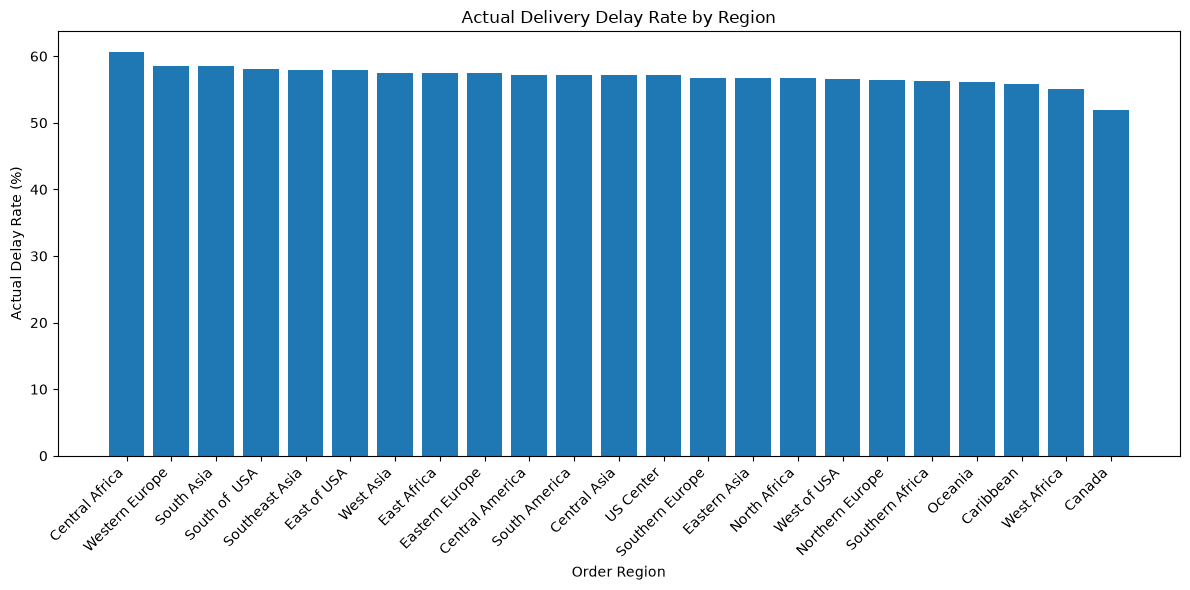

In [11]:
regional_delay_plot = regional_delay_analysis.dropna(
    subset=["Order Region"]
).sort_values(
    "Actual_Delay_Rate_%",
    ascending=False
)

plt.figure(figsize=(12, 6))

plt.bar(
    regional_delay_plot["Order Region"].astype(str),
    regional_delay_plot["Actual_Delay_Rate_%"]
)

plt.title("Actual Delivery Delay Rate by Region")
plt.xlabel("Order Region")
plt.ylabel("Actual Delay Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Calculate the overall benchmark

In [12]:
overall_delay_rate = (
    df_day8["Is_Delayed"].mean() * 100
)

print(
    "Overall Actual Delay Rate: "
    f"{overall_delay_rate:.2f}%"
)

Overall Actual Delay Rate: 57.28%


## State - Level Shipment Distribution

In [13]:
state_shipment_summary = (
    df_day8
    .groupby(
        ["Order Country", "Order State"],
        dropna=False
    )
    .size()
    .reset_index(name="Total_Shipments")
)

state_shipment_summary["Shipment_Share_%"] = (
    state_shipment_summary["Total_Shipments"]
    / len(df_day8)
    * 100
).round(2)

state_shipment_summary = state_shipment_summary.sort_values(
    "Total_Shipments",
    ascending=False
)

display(state_shipment_summary.head(20))

,Order Country,Order State,Total_Shipments,Shipment_Share_%
825,Reino Unido,Inglaterra,6722,3.72
349,Estados Unidos,California,4966,2.75
414,Francia,Isla de Francia,4580,2.54
18,Alemania,Renania del Norte-Westfalia,3303,1.83
320,El Salvador,San Salvador,3055,1.69
378,Estados Unidos,Nueva York,2753,1.53
387,Estados Unidos,Texas,2446,1.35
80,Australia,Nueva Gales del Sur,2370,1.31
682,México,Distrito Federal,2353,1.30
855,República Dominicana,Santo Domingo,2211,1.22


### Plot the 15 top highest-volume states

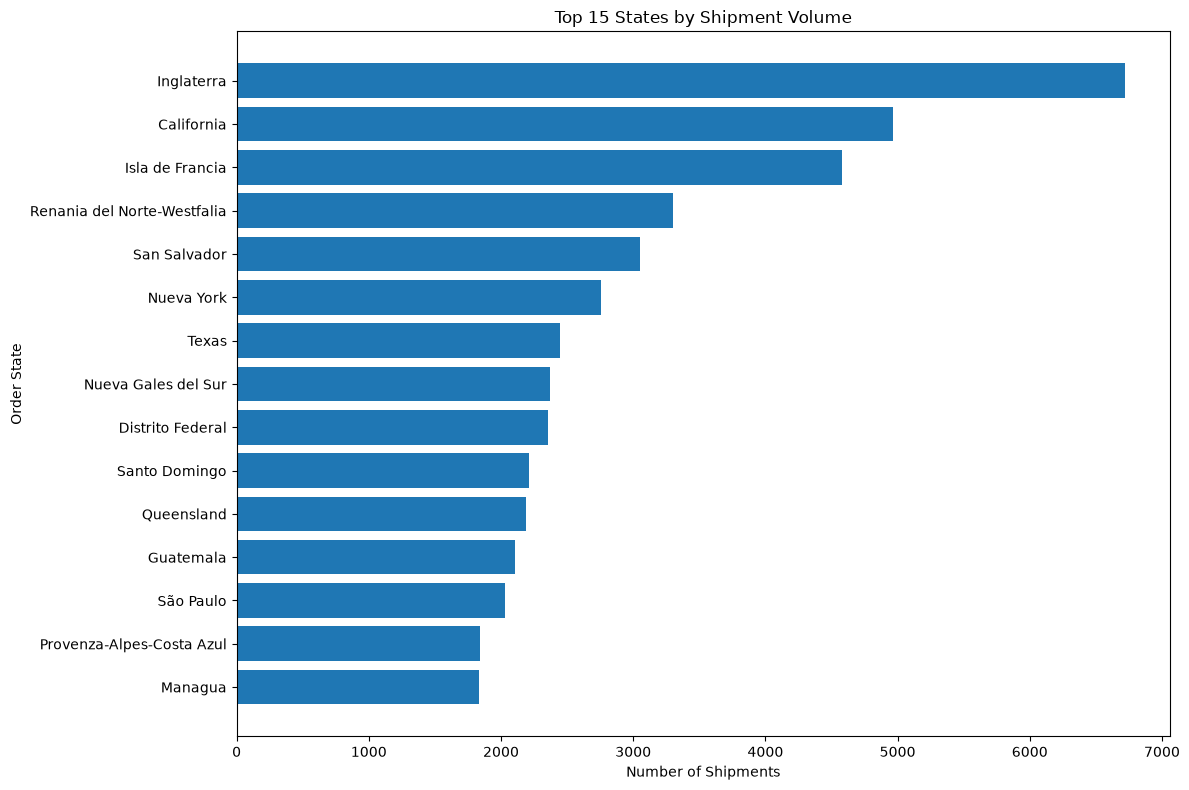

In [14]:
top_15_states = state_shipment_summary.dropna(
    subset=["Order State"]
).head(15).sort_values(
    "Total_Shipments",
    ascending=True
)

plt.figure(figsize=(12, 8))

plt.barh(
    top_15_states["Order State"].astype(str),
    top_15_states["Total_Shipments"]
)

plt.title("Top 15 States by Shipment Volume")
plt.xlabel("Number of Shipments")
plt.ylabel("Order State")
plt.tight_layout()
plt.show()

## State - Level Delay Analysis

In [15]:
state_delay_analysis = (
    df_day8
    .groupby(
        ["Order Country", "Order State"],
        dropna=False
    )
    .agg(
        Total_Shipments=("Is_Delayed", "size"),
        Delayed_Shipments=("Is_Delayed", "sum"),
        Average_Shipping_Variance_Days=(
            "Shipping_Delay_Days", "mean"
        ),
        Average_Actual_Shipping_Days=(
            "Days for shipping (real)", "mean"
        ),
        Average_Scheduled_Shipping_Days=(
            "Days for shipment (scheduled)", "mean"
        )
    )
    .reset_index()
)

state_delay_analysis["Actual_Delay_Rate_%"] = (
    state_delay_analysis["Delayed_Shipments"]
    / state_delay_analysis["Total_Shipments"]
    * 100
).round(2)

state_delay_analysis[
    "Average_Shipping_Variance_Days"
] = (
    state_delay_analysis[
        "Average_Shipping_Variance_Days"
    ].round(2)
)

state_delay_analysis["Average_Actual_Shipping_Days"] = (
    state_delay_analysis["Average_Actual_Shipping_Days"].round(2)
)

state_delay_analysis["Average_Scheduled_Shipping_Days"] = (
    state_delay_analysis["Average_Scheduled_Shipping_Days"].round(2)
)

state_delay_analysis = state_delay_analysis.sort_values(
    ["Actual_Delay_Rate_%", "Total_Shipments"],
    ascending=[False, False]
)

display(state_delay_analysis.head(20))

,Order Country,Order State,Total_Shipments,Delayed_Shipments,Average_Shipping_Variance_Days,Average_Actual_Shipping_Days,Average_Scheduled_Shipping_Days,Actual_Delay_Rate_%
840,República Democrática del Congo,Kivu del Sur,28,28,1.57,4.54,2.96,100.0
451,Hungría,Gy?r,25,25,1.36,3.92,2.56,100.0
1094,Venezuela,Vargas,21,21,2.33,4.76,2.43,100.0
300,Ecuador,Manabí,20,20,1.20,3.25,2.05,100.0
667,Mozambique,Manica,17,17,1.82,4.76,2.94,100.0
65,Argentina,Jujuy,14,14,1.00,3.43,2.43,100.0
833,República Checa,Ústí nad Labem,14,14,1.14,3.71,2.57,100.0
670,Mozambique,Niassa,12,12,1.08,2.17,1.08,100.0
970,Tanzania,Pwani,12,12,1.00,2.00,1.00,100.0
1026,Turquía,Nevsehir,12,12,2.00,4.17,2.17,100.0


## Identify the highest-delay states

In [16]:
print("Top 10 States by Actual Delay Rate")

display(
    state_delay_analysis.dropna(
        subset=["Order State"]
    ).head(10)
)

Top 10 States by Actual Delay Rate


,Order Country,Order State,Total_Shipments,Delayed_Shipments,Average_Shipping_Variance_Days,Average_Actual_Shipping_Days,Average_Scheduled_Shipping_Days,Actual_Delay_Rate_%
840,República Democrática del Congo,Kivu del Sur,28,28,1.57,4.54,2.96,100.0
451,Hungría,Gy?r,25,25,1.36,3.92,2.56,100.0
1094,Venezuela,Vargas,21,21,2.33,4.76,2.43,100.0
300,Ecuador,Manabí,20,20,1.20,3.25,2.05,100.0
667,Mozambique,Manica,17,17,1.82,4.76,2.94,100.0
65,Argentina,Jujuy,14,14,1.00,3.43,2.43,100.0
833,República Checa,Ústí nad Labem,14,14,1.14,3.71,2.57,100.0
670,Mozambique,Niassa,12,12,1.08,2.17,1.08,100.0
970,Tanzania,Pwani,12,12,1.00,2.00,1.00,100.0
1026,Turquía,Nevsehir,12,12,2.00,4.17,2.17,100.0


### Identify the lowest-delay states

In [17]:
print("Bottom 10 States by Actual Delay Rate")

display(
    state_delay_analysis.dropna(
        subset=["Order State"]
    ).sort_values(
        "Actual_Delay_Rate_%",
        ascending=True
    ).head(10)
)

Bottom 10 States by Actual Delay Rate


,Order Country,Order State,Total_Shipments,Delayed_Shipments,Average_Shipping_Variance_Days,Average_Actual_Shipping_Days,Average_Scheduled_Shipping_Days,Actual_Delay_Rate_%
962,Tanzania,Iringa,1,0,0.00,4.00,4.00,0.0
916,Sierra Leona,Oriental,1,0,-1.00,3.00,4.00,0.0
914,Serbia,Serbia Central,1,0,-1.00,3.00,4.00,0.0
55,Argelia,Tizi Ouzou,8,0,-0.50,3.50,4.00,0.0
181,Camerún,Ouest del Sur,8,0,-0.50,3.50,4.00,0.0
767,Omán,Mascate,8,0,-0.50,3.50,4.00,0.0
1048,Ucrania,Ivano-Frankivsk,19,0,-0.74,1.68,2.42,0.0
790,Perú,Ancash,17,0,-0.47,2.12,2.59,0.0
436,Guinea,Kindia,6,0,-0.50,3.50,4.00,0.0
507,Irak,Diala,6,0,-1.00,3.00,4.00,0.0


### Important precaution

In [18]:
MIN_STATE_SHIPMENTS = 100

state_delay_analysis_reliable = (
    state_delay_analysis[
        state_delay_analysis["Total_Shipments"] >= MIN_STATE_SHIPMENTS
    ]
    .sort_values(
        ["Actual_Delay_Rate_%", "Total_Shipments"],
        ascending=[False, False]
    )
    .copy()
)

display(state_delay_analysis_reliable.head(20))

,Order Country,Order State,Total_Shipments,Delayed_Shipments,Average_Shipping_Variance_Days,Average_Actual_Shipping_Days,Average_Scheduled_Shipping_Days,Actual_Delay_Rate_%
845,República Dominicana,Duarte,161,122,1.06,3.98,2.91,75.78
555,Italia,Liguria,129,97,1.26,3.93,2.67,75.19
167,Bélgica,Flanders Oriental,123,92,1.08,3.88,2.80,74.80
301,Ecuador,Pichincha,136,101,0.78,3.19,2.41,74.26
430,Guatemala,Escuintla,171,123,0.77,3.04,2.27,71.93
212,China,Henan,230,164,1.03,3.52,2.49,71.30
270,Costa de Marfil,Lagunes,188,134,1.04,3.53,2.49,71.28
1046,Ucrania,Dnipropetrovsk,146,103,0.99,3.60,2.61,70.55
129,Brasil,Distrito Federal,206,145,0.93,3.71,2.78,70.39
998,Turquía,Bursa,134,94,0.87,3.22,2.35,70.15


## Compare Regional Performance

In [19]:
regional_performance = regional_delay_analysis.copy()

regional_performance["Performance_Category"] = np.select(
    [
        (
            (regional_performance["Total_Shipments"]
             >= regional_performance["Total_Shipments"].median())
            &
            (regional_performance["Actual_Delay_Rate_%"]
             > overall_delay_rate)
        ),
        (
            (regional_performance["Total_Shipments"]
             >= regional_performance["Total_Shipments"].median())
            &
            (regional_performance["Actual_Delay_Rate_%"]
             <= overall_delay_rate)
        ),
        (
            (regional_performance["Total_Shipments"]
             < regional_performance["Total_Shipments"].median())
            &
            (regional_performance["Actual_Delay_Rate_%"]
             > overall_delay_rate)
        )
    ],
    [
        "High Volume - Above Average Delay",
        "High Volume - At or Below Average Delay",
        "Lower Volume - Above Average Delay"
    ],
    default="Lower Volume - At or Below Average Delay"
)

display(
    regional_performance[
        [
            "Order Region",
            "Total_Shipments",
            "Delayed_Shipments",
            "Actual_Delay_Rate_%",
            "Average_Delay_Days",
            "Performance_Category"
        ]
    ]
)

,Order Region,Total_Shipments,Delayed_Shipments,Actual_Delay_Rate_%,Average_Delay_Days,Performance_Category
2,Central Africa,1677,1018,60.70,0.64,Lower Volume - Above Average Delay
22,Western Europe,27109,15863,58.52,0.60,High Volume - Above Average Delay
13,South Asia,7731,4523,58.50,0.60,High Volume - Above Average Delay
14,South of USA,4045,2350,58.10,0.58,Lower Volume - Above Average Delay
15,Southeast Asia,9539,5531,57.98,0.56,High Volume - Above Average Delay
6,East of USA,6915,4009,57.98,0.58,High Volume - Above Average Delay
20,West Asia,6009,3455,57.50,0.57,Lower Volume - Above Average Delay
5,East Africa,1852,1064,57.45,0.57,Lower Volume - Above Average Delay
8,Eastern Europe,3920,2252,57.45,0.58,Lower Volume - Above Average Delay
3,Central America,28341,16224,57.25,0.56,High Volume - At or Below Average Delay


## Analyze Delay Performance by Region and State Together

In [20]:
region_state_analysis = (
    df_day8
    .groupby(
        ["Order Country", "Order Region", "Order State"],
        dropna=False
    )
    .agg(
        Total_Shipments=("Is_Delayed", "size"),
        Delayed_Shipments=("Is_Delayed", "sum"),
        Average_Shipping_Variance_Days=(
            "Shipping_Delay_Days", "mean"
        )
    )
    .reset_index()
)

region_state_analysis["Actual_Delay_Rate_%"] = (
    region_state_analysis["Delayed_Shipments"]
    / region_state_analysis["Total_Shipments"]
    * 100
).round(2)

region_state_analysis[
    "Average_Shipping_Variance_Days"
] = (
    region_state_analysis[
        "Average_Shipping_Variance_Days"
    ].round(2)
)

region_state_analysis = region_state_analysis.sort_values(
    ["Actual_Delay_Rate_%", "Total_Shipments"],
    ascending=[False, False]
)

display(region_state_analysis.head(25))

,Order Country,Order Region,Order State,Total_Shipments,Delayed_Shipments,Average_Shipping_Variance_Days,Actual_Delay_Rate_%
840,República Democrática del Congo,Central Africa,Kivu del Sur,28,28,1.57,100.0
451,Hungría,Eastern Europe,Gy?r,25,25,1.36,100.0
1094,Venezuela,South America,Vargas,21,21,2.33,100.0
300,Ecuador,South America,Manabí,20,20,1.20,100.0
667,Mozambique,East Africa,Manica,17,17,1.82,100.0
65,Argentina,South America,Jujuy,14,14,1.00,100.0
833,República Checa,Eastern Europe,Ústí nad Labem,14,14,1.14,100.0
670,Mozambique,East Africa,Niassa,12,12,1.08,100.0
970,Tanzania,East Africa,Pwani,12,12,1.00,100.0
1026,Turquía,West Asia,Nevsehir,12,12,2.00,100.0


## Day 8 KPI Summary

In [21]:
# Highest delay region
highest_delay_region = (
    regional_delay_analysis.dropna(
        subset=["Order Region"]
    )
    .sort_values(
        ["Actual_Delay_Rate_%", "Total_Shipments"],
        ascending=[False, False]
    )
    .iloc[0]["Order Region"]
)

# Lowest delay region
lowest_delay_region = (
    regional_delay_analysis.dropna(
        subset=["Order Region"]
    )
    .sort_values(
        ["Actual_Delay_Rate_%", "Total_Shipments"],
        ascending=[True, False]
    )
    .iloc[0]["Order Region"]
)

# Highest delay state with a minimum of 100 shipments
highest_delay_state = (
    f"{state_delay_analysis_reliable.iloc[0]['Order State']}, "
    f"{state_delay_analysis_reliable.iloc[0]['Order Country']}"
    if not state_delay_analysis_reliable.empty
    else "Unavailable"
)

# Highest-volume region
highest_volume_region = (
    regional_shipment_summary.dropna(
        subset=["Order Region"]
    )
    .iloc[0]["Order Region"]
)

# Highest-volume state, identified by both state and country
top_state_row = (
    state_shipment_summary.dropna(
        subset=["Order Country", "Order State"]
    )
    .iloc[0]
)

highest_volume_state = (
    f"{top_state_row['Order State']}, "
    f"{top_state_row['Order Country']}"
)

# Count unique country-state combinations
unique_country_state_combinations = (
    df_day8[["Order Country", "Order State"]]
    .dropna(subset=["Order Country", "Order State"])
    .drop_duplicates()
    .shape[0]
)

# Create KPI summary
day8_kpis = pd.DataFrame({
    "Metric": [
        "Total Shipment Records",
        "Unique Regions",
        "Unique Country-State Combinations",
        "Overall Actual Delay Rate (%)",
        "Total Delayed Shipments",
        "Highest Delay Region",
        "Lowest Delay Region",
        "Highest Delay State (Minimum 100 Shipments)",
        "Highest Volume Region",
        "Highest Volume State"
    ],

    "Value": [
        len(df_day8),
        df_day8["Order Region"].nunique(dropna=True),
        unique_country_state_combinations,
        round(overall_delay_rate, 2),
        int(df_day8["Is_Delayed"].sum()),
        highest_delay_region,
        lowest_delay_region,
        highest_delay_state,
        highest_volume_region,
        highest_volume_state
    ]
})

display(day8_kpis)

,Metric,Value
0,Total Shipment Records,180519
1,Unique Regions,23
2,Unique Country-State Combinations,1117
3,Overall Actual Delay Rate (%),57.28
4,Total Delayed Shipments,103400
5,Highest Delay Region,Central Africa
6,Lowest Delay Region,Canada
7,Highest Delay State (Minimum 100 Shipments),"Duarte, República Dominicana"
8,Highest Volume Region,Central America
9,Highest Volume State,"Inglaterra, Reino Unido"


## Validate the Results

### Regional shipment totals

In [22]:
regional_total = regional_shipment_summary[
    "Total_Shipments"
].sum()

print("Original shipment count:", len(df_day8))
print("Regional shipment count:", regional_total)

print(
    "Regional totals match:",
    regional_total == len(df_day8)
)

Original shipment count: 180519
Regional shipment count: 180519
Regional totals match: True


### State shipment totals

In [23]:
state_total = state_shipment_summary[
    "Total_Shipments"
].sum()

print("Original shipment count:", len(df_day8))
print("State shipment count:", state_total)

print(
    "State totals match:",
    state_total == len(df_day8)
)

Original shipment count: 180519
State shipment count: 180519
State totals match: True


### Validate delay rates

In [24]:
valid_delay_values = (
    df_day8["Is_Delayed"]
    .dropna()
    .isin([0, 1])
    .all()
)

print(
    "Is_Delayed contains only 0 and 1:",
    valid_delay_values
)

print(
    "Missing Is_Delayed values:",
    df_day8["Is_Delayed"].isna().sum()
)

Is_Delayed contains only 0 and 1: True
Missing Is_Delayed values: 0


### Regional delay-rate range

In [25]:
print(
    "Minimum regional delay rate:",
    regional_delay_analysis[
        "Actual_Delay_Rate_%"
    ].min()
)

print(
    "Maximum regional delay rate:",
    regional_delay_analysis[
        "Actual_Delay_Rate_%"
    ].max()
)

Minimum regional delay rate: 51.93
Maximum regional delay rate: 60.7


### Calculate required outputs exists

In [26]:
day8_validation_report = pd.DataFrame({
    "Validation_Check": [
        "Dataset Loaded",
        "Required Columns Available",
        "Regional Shipment Totals Match",
        "State Shipment Totals Match",
        "Delay Flag Valid",
        "Regional Delay Analysis Available",
        "State Delay Analysis Available",
        "KPI Summary Available"
    ],

    "Result": [
        "PASS" if not df_day8.empty else "FAIL",

        "PASS" if not missing_columns else "FAIL",

        "PASS" if regional_total == len(df_day8) else "FAIL",

        "PASS" if state_total == len(df_day8) else "FAIL",

        "PASS" if valid_delay_values else "FAIL",

        "PASS" if not regional_delay_analysis.empty else "FAIL",

        "PASS" if not state_delay_analysis.empty else "FAIL",

        "PASS" if not day8_kpis.empty else "FAIL"
    ]
})

display(day8_validation_report)

,Validation_Check,Result
0,Dataset Loaded,PASS
1,Required Columns Available,PASS
2,Regional Shipment Totals Match,PASS
3,State Shipment Totals Match,PASS
4,Delay Flag Valid,PASS
5,Regional Delay Analysis Available,PASS
6,State Delay Analysis Available,PASS
7,KPI Summary Available,PASS


In [27]:
# Validate that regional totals match the source dataset
regional_total = regional_shipment_summary["Total_Shipments"].sum()

# Validate that country-state totals match the source dataset
state_total = state_shipment_summary["Total_Shipments"].sum()

# Validate regional delay rates
regional_rates_valid = (
    regional_delay_analysis["Actual_Delay_Rate_%"]
    .dropna()
    .between(0, 100)
    .all()
)

# Validate state-level delay rates
state_rates_valid = (
    state_delay_analysis["Actual_Delay_Rate_%"]
    .dropna()
    .between(0, 100)
    .all()
)

# Validate the overall delayed-shipment count
delayed_count_valid = (
    int(df_day8["Is_Delayed"].sum())
    == int(df_day8["Is_Delayed"].eq(1).sum())
)

print("Regional totals match:", regional_total == len(df_day8))
print("Country-state totals match:", state_total == len(df_day8))
print("Regional delay rates valid:", regional_rates_valid)
print("State delay rates valid:", state_rates_valid)
print("Delayed shipment count valid:", delayed_count_valid)

Regional totals match: True
Country-state totals match: True
Regional delay rates valid: True
State delay rates valid: True
Delayed shipment count valid: True


## Saving Day 8 work

In [28]:
day8_output_dir = "../data/analysis_data/"

day8_outputs = {
    "APL_Day8_Regional_Shipment_Summary.csv":
        regional_shipment_summary,

    "APL_Day8_Regional_Delay_Analysis.csv":
        regional_delay_analysis,

    "APL_Day8_Regional_Delay_Severity.csv":
        regional_severity_analysis,

    "APL_Day8_State_Shipment_Summary.csv":
        state_shipment_summary,

    "APL_Day8_State_Delay_Analysis.csv":
        state_delay_analysis,

    "APL_Day8_State_Delay_Analysis_Min100.csv":
        state_delay_analysis_reliable,

    "APL_Day8_Regional_Performance.csv":
        regional_performance,

    "APL_Day8_Region_State_Analysis.csv":
        region_state_analysis,

    "APL_Day8_KPIs.csv":
        day8_kpis,

    "APL_Day8_Validation.csv":
        day8_validation_report
}

In [29]:
from pathlib import Path

output_directory = Path(day8_output_dir)

if not output_directory.exists():
    raise FileNotFoundError(
        f"Output directory does not exist: {output_directory}"
    )

for filename, output_df in day8_outputs.items():

    output_path = output_directory / filename

    output_df.to_csv(
        output_path,
        index=False,
        encoding="utf-8"
    )

    print("Saved:", output_path)

print("\nAll Day 8 outputs saved successfully.")

Saved: ..\data\analysis_data\APL_Day8_Regional_Shipment_Summary.csv
Saved: ..\data\analysis_data\APL_Day8_Regional_Delay_Analysis.csv
Saved: ..\data\analysis_data\APL_Day8_Regional_Delay_Severity.csv
Saved: ..\data\analysis_data\APL_Day8_State_Shipment_Summary.csv
Saved: ..\data\analysis_data\APL_Day8_State_Delay_Analysis.csv
Saved: ..\data\analysis_data\APL_Day8_State_Delay_Analysis_Min100.csv
Saved: ..\data\analysis_data\APL_Day8_Regional_Performance.csv
Saved: ..\data\analysis_data\APL_Day8_Region_State_Analysis.csv
Saved: ..\data\analysis_data\APL_Day8_KPIs.csv
Saved: ..\data\analysis_data\APL_Day8_Validation.csv

All Day 8 outputs saved successfully.
